In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                     # same seed everywhere, so results can be repeated
np.random.seed(SEED)

DATA_PATH = "data/Epileptic Seizure Recognition.csv"
SIGNAL_COLS = [f"X{i}" for i in range(1, 179)]     # X1 ... X178

## Part A: Understand the data
### A1. Load the data
Check the shape, missing values and number of rows per label.
**Result:** 11,500 rows × 180 columns, 0 missing values, 2,300 rows for each of the 5 labels.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={df.columns[0]: "id"})     # first column is the segment ID

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nRows per original label:")
print(df["y"].value_counts().sort_index())

Shape: (11500, 180)
Missing values: 0

Rows per original label:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64


### A2. Find the recording ID
The ID `X21.V1.791` = chunk `X21` + recording `V1.791`. We keep the recording part.
**Result:** 500 recordings, each with exactly 23 rows and one label.

In [3]:
df["recording_id"] = df["id"].str.split(".", n=1).str[1]

per_recording = df.groupby("recording_id")
print("Number of recordings :", df["recording_id"].nunique())
print("Rows per recording   :", per_recording.size().unique())
print("Labels per recording :", per_recording["y"].nunique().unique())

Number of recordings : 500
Rows per recording   : [23]
Labels per recording : [1]


### A3. Make the binary target
`seizure = 1` if `y == 1`, otherwise `0` (labels 2–5 are all non-seizure).
**Result:** 20% seizure. Always saying "no seizure" already gives **80% accuracy**, so accuracy is a weak metric here.

In [4]:
df["seizure"] = (df["y"] == 1).astype(int)

print(df["seizure"].value_counts())
print("Seizure rows: %.1f%%" % (df["seizure"].mean() * 100))
print("Accuracy if we always say 'no seizure': %.1f%%" % ((1 - df["seizure"].mean()) * 100))

seizure
0    9200
1    2300
Name: count, dtype: int64
Seizure rows: 20.0%
Accuracy if we always say 'no seizure': 80.0%


## Part B: Split without leakage
### B1. Split by recording (60 / 20 / 20)
We split **recordings**, not rows, so all 23 chunks of a recording stay in one set. Otherwise the model could "recognise" a recording it saw in training, and test results would look too good.

In [6]:
from sklearn.model_selection import train_test_split

recordings = df.groupby("recording_id")["y"].first()      # 500 recordings and their labels

train_ids, temp_ids = train_test_split(recordings.index, test_size=0.4,
                                       stratify=recordings, random_state=SEED)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5,
                                     stratify=recordings[temp_ids], random_state=SEED)

train = df[df["recording_id"].isin(train_ids)]
val   = df[df["recording_id"].isin(val_ids)]
test  = df[df["recording_id"].isin(test_ids)]

### B2. Check the split
**Result:** no recording appears in two sets. Train = 300 recordings, validation = 100, test = 100, each 20% seizure.

In [7]:
# No recording should be in two sets
print("Train ∩ Val :", len(set(train_ids) & set(val_ids)))
print("Train ∩ Test:", len(set(train_ids) & set(test_ids)))
print("Val ∩ Test  :", len(set(val_ids) & set(test_ids)))

pd.DataFrame({
    "rows":       [len(train), len(val), len(test)],
    "recordings": [train["recording_id"].nunique(), val["recording_id"].nunique(), test["recording_id"].nunique()],
    "seizure %":  [train["seizure"].mean() * 100, val["seizure"].mean() * 100, test["seizure"].mean() * 100],
}, index=["train", "val", "test"])

Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0


,rows,recordings,seizure %
train,6900,300,20.0
val,2300,100,20.0
test,2300,100,20.0


### B3. Scale the data
The scaler learns the mean and std from the **training set only**, then applies them to validation and test, so no information leaks.

In [ ]:
from sklearn.preprocessing import StandardScaler

X_train, y_train = train[SIGNAL_COLS].values, train["seizure"].values
X_val,   y_val   = val[SIGNAL_COLS].values,   val["seizure"].values
X_test,  y_test  = test[SIGNAL_COLS].values,  test["seizure"].values

scaler = StandardScaler().fit(X_train)       # fit on train only
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

## Part C: Baseline, then improve step by step
### Common training + evaluation function
Every model goes through the same function: **train → predict on validation → metrics → 4 plots** (confusion matrix, ROC, precision-recall, calibration).
Metrics: accuracy, sensitivity, specificity, PPV, NPV, ROC-AUC, PR-AUC, Brier score.

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.calibration import CalibrationDisplay

def get_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)            # yes / no
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "accuracy": (tp + tn) / len(y_true),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "PPV": tp / max(tp + fp, 1),                  # max(..., 1) avoids dividing by 0
        "NPV": tn / max(tn + fn, 1),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

results = {}     # metrics of every model
val_probs = {}   # validation probabilities of every model

def train_and_evaluate(name, model, X_tr, X_v):
    model.fit(X_tr, y_train)                          # 1. train
    prob = model.predict_proba(X_v)[:, 1]             # 2. probability of seizure
    pred = (prob >= 0.5).astype(int)                  # 3. yes / no
    results[name] = get_metrics(y_val, prob)          # 4. metrics
    val_probs[name] = prob

    fig, ax = plt.subplots(1, 4, figsize=(18, 4))     # 5. plots
    ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=["no seizure", "seizure"],
                                            cmap="Blues", colorbar=False, ax=ax[0])
    RocCurveDisplay.from_predictions(y_val, prob, ax=ax[1])
    PrecisionRecallDisplay.from_predictions(y_val, prob, ax=ax[2])
    CalibrationDisplay.from_predictions(y_val, prob, n_bins=10, ax=ax[3])
    ax[0].set_title("Confusion matrix (threshold 0.5)")
    ax[1].set_title("ROC curve")
    ax[2].set_title("Precision-recall curve")
    ax[3].set_title("Calibration curve")
    fig.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results).T.round(4)           # table of all models so far

### Step 1 — Baseline: Logistic Regression (raw values)
**Result:** caught only **57 of 460 seizures**, ROC-AUC **0.52** (like guessing).
**Problem:** a linear model can't measure **wave size**; up and down values cancel out.
**Next change:** use a non-linear model.

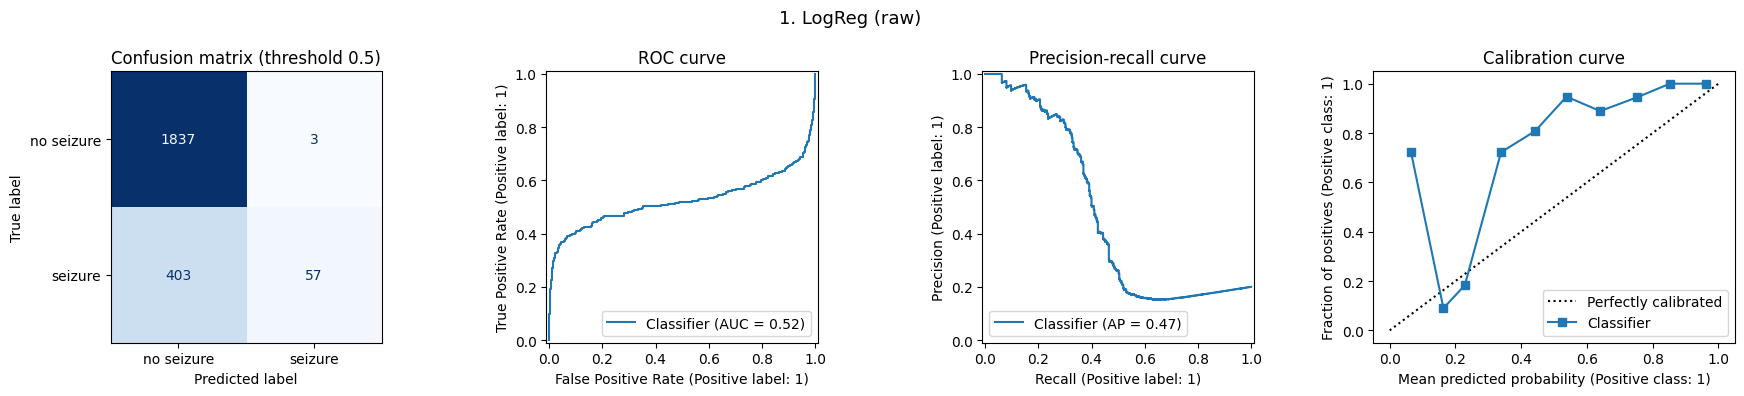

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.95,0.8201,0.5245,0.4701,0.1487


In [10]:
from sklearn.linear_model import LogisticRegression

model_1 = LogisticRegression(max_iter=1000, random_state=SEED)
train_and_evaluate("1. LogReg (raw)", model_1, X_train_s, X_val_s)

### Step 2 — Change the model: Random Forest (raw values)
300 decision trees vote together. Trees can learn rules like "is any value very large?".
**Result:** all 460 seizures caught, but **16 false alarms**, and the probabilities are under-confident.
**Next change:** boosting, where trees fix each other's mistakes.

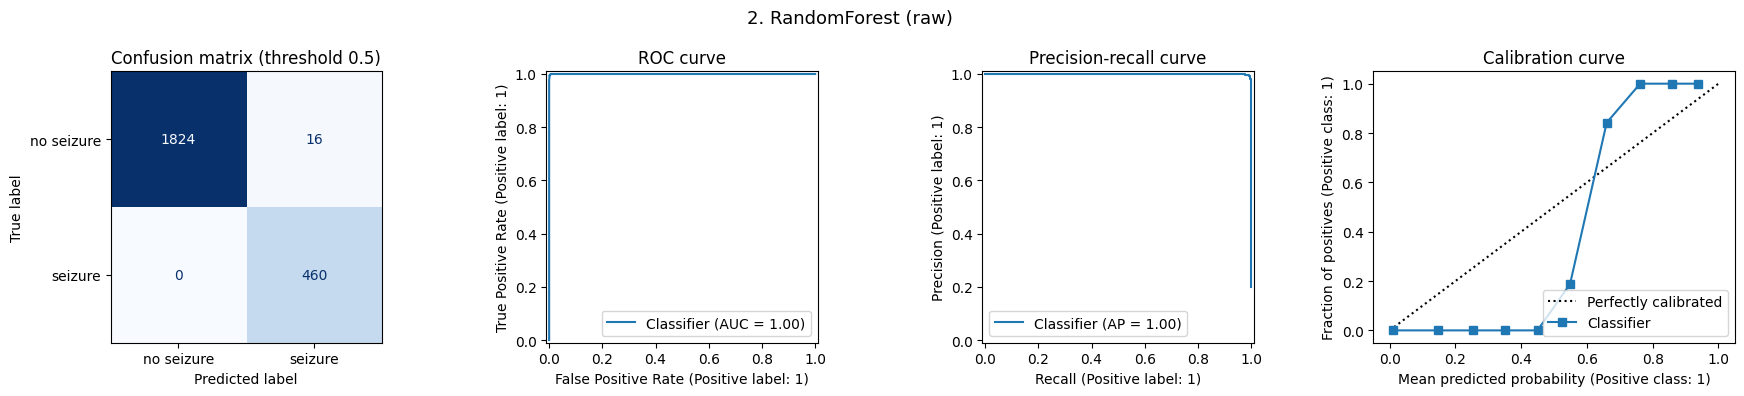

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128


In [11]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=300, random_state=SEED)
train_and_evaluate("2. RandomForest (raw)", model_2, X_train, X_val)

### Step 3 — Change the model: LightGBM (raw values)
Trees are built one after another; each new tree fixes the errors of the previous ones.
**Result:** **1 missed, only 4 false alarms**, best calibration (Brier 0.002). ⭐ **Best model.**
**Next change:** try engineered features, which are easier to explain.

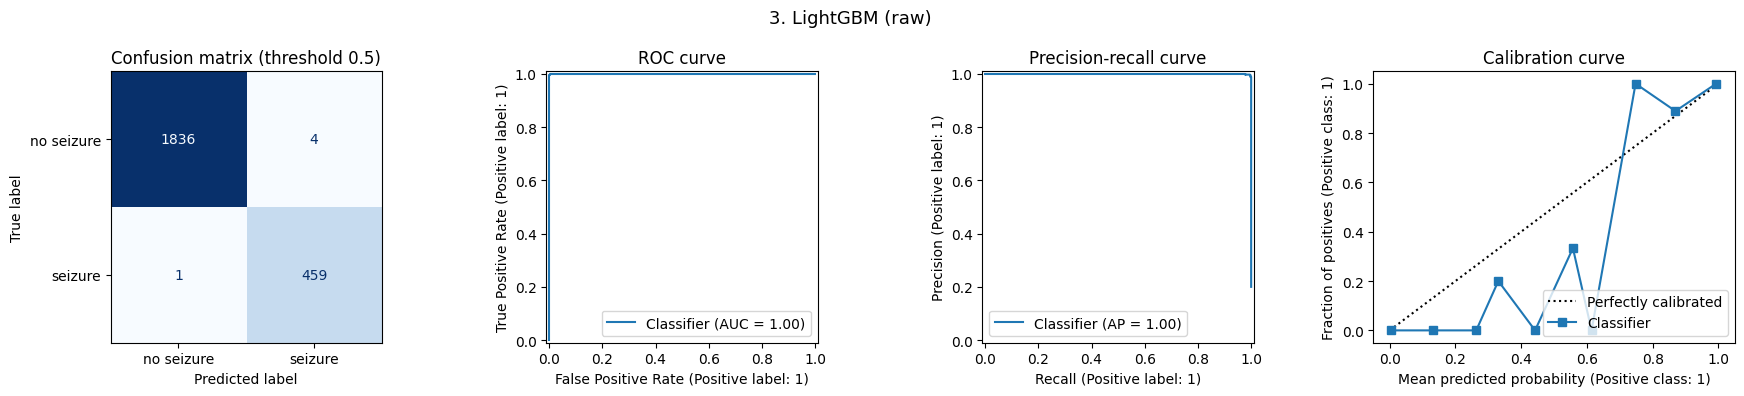

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020


In [12]:
from lightgbm import LGBMClassifier

model_3 = LGBMClassifier(random_state=SEED, verbose=-1)
train_and_evaluate("3. LightGBM (raw)", model_3, X_train, X_val)

### Step 4 — Change the input: engineered features
13 numbers per segment: mean, std, min, max, range, energy, zero-crossings, line length, and power in 5 EEG bands (delta, theta, alpha, beta, gamma).

In [13]:
from scipy.signal import welch

FS = 173.61
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 60)}

def make_features(X):
    f = pd.DataFrame()
    f["mean"] = X.mean(axis=1)
    f["std"] = X.std(axis=1)
    f["min"] = X.min(axis=1)
    f["max"] = X.max(axis=1)
    f["range"] = f["max"] - f["min"]
    f["energy"] = (X ** 2).sum(axis=1)
    centred = X - X.mean(axis=1, keepdims=True)
    f["zero_crossings"] = (np.diff(np.sign(centred), axis=1) != 0).sum(axis=1)
    f["line_length"] = np.abs(np.diff(X, axis=1)).sum(axis=1)
    freqs, power = welch(X, fs=FS, nperseg=178, axis=1)
    for band, (low, high) in BANDS.items():
        f[band] = power[:, (freqs >= low) & (freqs < high)].sum(axis=1)
    return f

F_train, F_val, F_test = make_features(X_train), make_features(X_val), make_features(X_test)
F_train.head()

,mean,std,min,max,range,energy,zero_crossings,line_length,delta,theta,alpha,beta,gamma
0,-16.910112,95.710958,-281,229,510,1681484,25,5700,2970.781119,145.912733,4737.337289,3834.410487,79.627925
1,-44.044944,44.186380,-126,80,206,692846,24,2458,400.713841,338.813455,285.072049,482.780025,8.832193
2,13.988764,64.883300,-137,141,278,784184,21,3753,167.332136,176.812835,2015.138321,368.436763,5.318075
3,-32.544944,37.104782,-118,39,157,433597,3,858,1015.442757,270.864897,40.713407,23.282059,1.531479
4,-31.685393,151.798809,-400,419,819,4280338,12,5320,2468.223005,13466.191117,912.586655,1026.254146,45.268356


### Step 4a — Logistic Regression on features
Same model as the baseline, only the input changes (features scaled on the training set).
**Result:** ROC-AUC jumps **0.52 → 0.999**. The baseline's problem was the **input**, not the model.

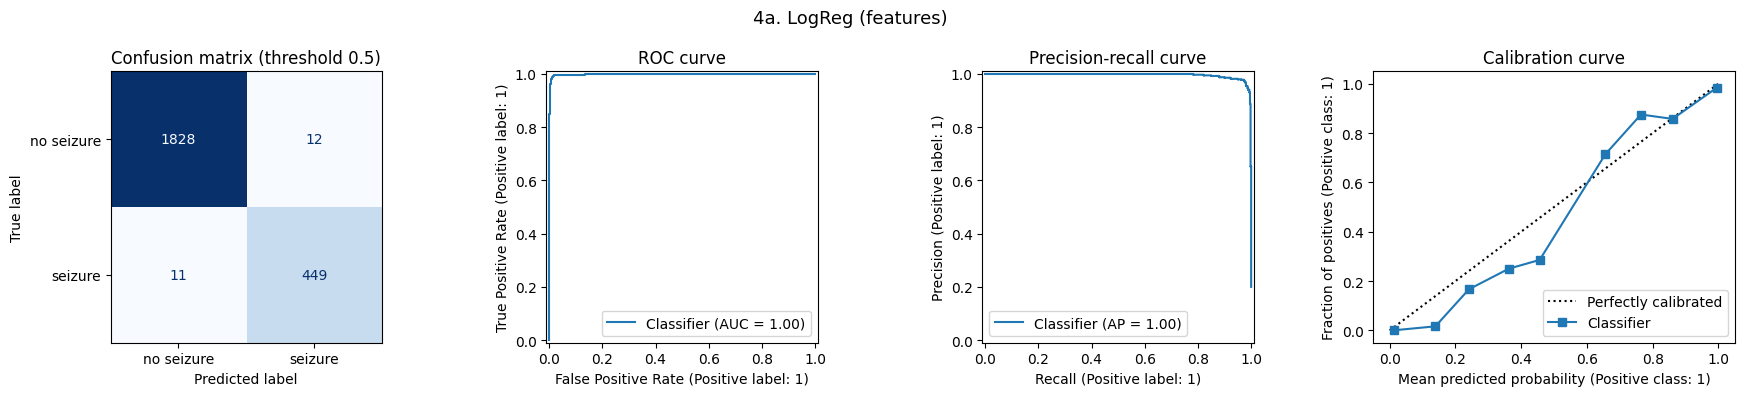

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9960,0.0095


In [14]:
feat_scaler = StandardScaler().fit(F_train)
F_train_s, F_val_s, F_test_s = feat_scaler.transform(F_train), feat_scaler.transform(F_val), feat_scaler.transform(F_test)

model_4a = LogisticRegression(max_iter=1000, random_state=SEED)
train_and_evaluate("4a. LogReg (features)", model_4a, F_train_s, F_val_s)

### Step 4b — LightGBM on features
**Result:** 6 missed, 18 false alarms, slightly **worse than LightGBM on raw values**, because the features lose some wave-shape detail.
**Next change:** let a model learn its own features.

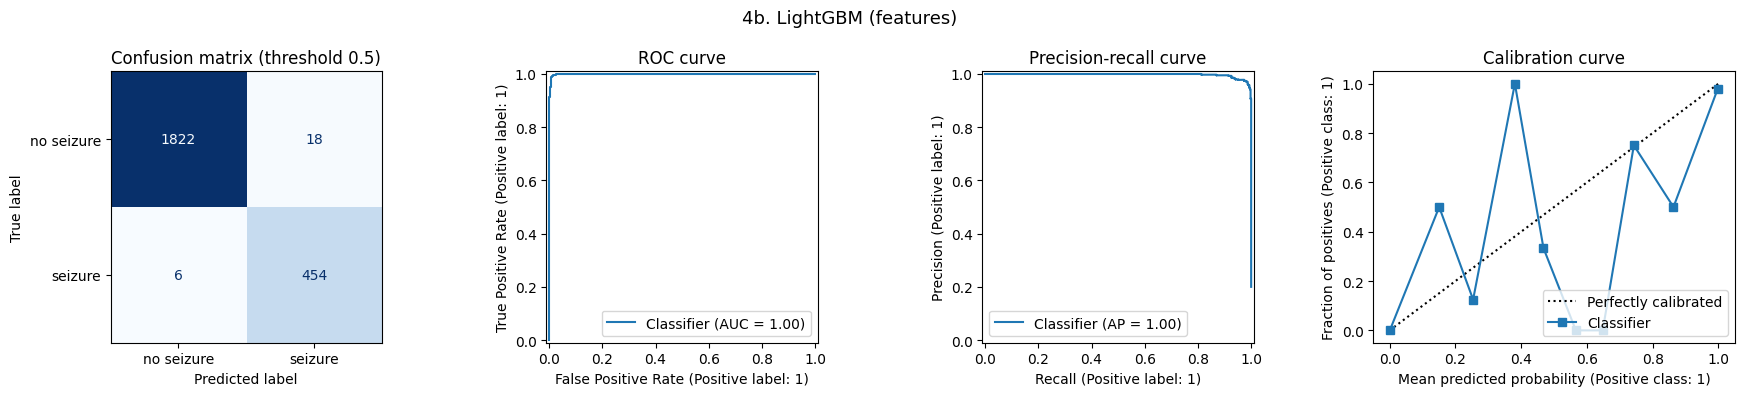

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9960,0.0095
4b. LightGBM (features),454.0,18.0,1822.0,6.0,0.9896,0.9870,0.9902,0.9619,0.9967,0.9994,0.9976,0.0081


In [15]:
model_4b = LGBMClassifier(random_state=SEED, verbose=-1)
train_and_evaluate("4b. LightGBM (features)", model_4b, F_train, F_val)

### Step 5 — Change the approach: 1D CNN (deep learning)
The network learns its own patterns from the raw signal. It has 3 convolution layers, then a max-pool that finds the pattern anywhere in the segment.
The `fit` method contains the **training loop**: shuffle → mini-batch → predict → loss → backward → update weights.

In [16]:
import torch
import torch.nn as nn

class CNN1D:
    def __init__(self, epochs=20, batch_size=64):
        torch.manual_seed(SEED)
        self.epochs, self.batch_size = epochs, batch_size
        # shapes are (channels, length) for one segment
        self.net = nn.Sequential(
            # Block 1: find small wave shapes
            nn.Conv1d(1, 16, kernel_size=7, padding=3),    # (1, 178)  -> (16, 178)  16 filters, each 7 values wide
            nn.ReLU(),                                     # (16, 178) -> (16, 178)  keep positive matches only
            nn.MaxPool1d(2),                               # (16, 178) -> (16, 89)   halve the length

            # Block 2: combine small shapes into bigger patterns
            nn.Conv1d(16, 32, kernel_size=5, padding=2),   # (16, 89)  -> (32, 89)
            nn.ReLU(),                                     # (32, 89)  -> (32, 89)
            nn.MaxPool1d(2),                               # (32, 89)  -> (32, 44)

            # Block 3: even more complex patterns
            nn.Conv1d(32, 64, kernel_size=3, padding=1),   # (32, 44)  -> (64, 44)
            nn.ReLU(),                                     # (64, 44)  -> (64, 44)
            nn.AdaptiveMaxPool1d(1),                       # (64, 44)  -> (64, 1)    strongest match anywhere in the segment

            # Classifier
            nn.Flatten(),                                  # (64, 1)   -> (64,)
            nn.Linear(64, 1),                              # (64,)     -> (1,)       one score: seizure or not
        )

    def to_tensor(self, X):
        return torch.tensor(X / self.scale, dtype=torch.float32).unsqueeze(1)   # shape (n, 1, 178)

    def fit(self, X, y):
        self.scale = X.std()                                   # from training data only
        Xt, yt = self.to_tensor(X), torch.tensor(y, dtype=torch.float32)
        optimizer = torch.optim.Adam(self.net.parameters(), lr=1e-3)
        loss_fn = nn.BCEWithLogitsLoss()

        for epoch in range(self.epochs):                       # training loop
            order = torch.randperm(len(Xt))                    # shuffle
            total_loss = 0
            for i in range(0, len(Xt), self.batch_size):       # mini-batches
                batch = order[i:i + self.batch_size]
                loss = loss_fn(self.net(Xt[batch]).squeeze(1), yt[batch])   # predict + error
                optimizer.zero_grad()
                loss.backward()                                # how to change each weight
                optimizer.step()                               # update weights
                total_loss += loss.item() * len(batch)
            print(f"epoch {epoch + 1:2d}   loss = {total_loss / len(Xt):.4f}")
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            p = torch.sigmoid(self.net(self.to_tensor(X))).squeeze(1).numpy()
        return np.column_stack([1 - p, p])                     # same format as sklearn

### Step 5 — Train the CNN
**Result:** the loss falls from 0.31 to 0.04, but **22 false alarms**, and the model is over-confident.
**Finding:** deep learning doesn't beat LightGBM here. A more complex model is not automatically better.

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


epoch  1   loss = 0.3087


epoch  2   loss = 0.1155


epoch  3   loss = 0.0998


epoch  4   loss = 0.0911


...

epoch 16   loss = 0.0480


epoch 17   loss = 0.0451


epoch 18   loss = 0.0438


epoch 19   loss = 0.0431


epoch 20   loss = 0.0417


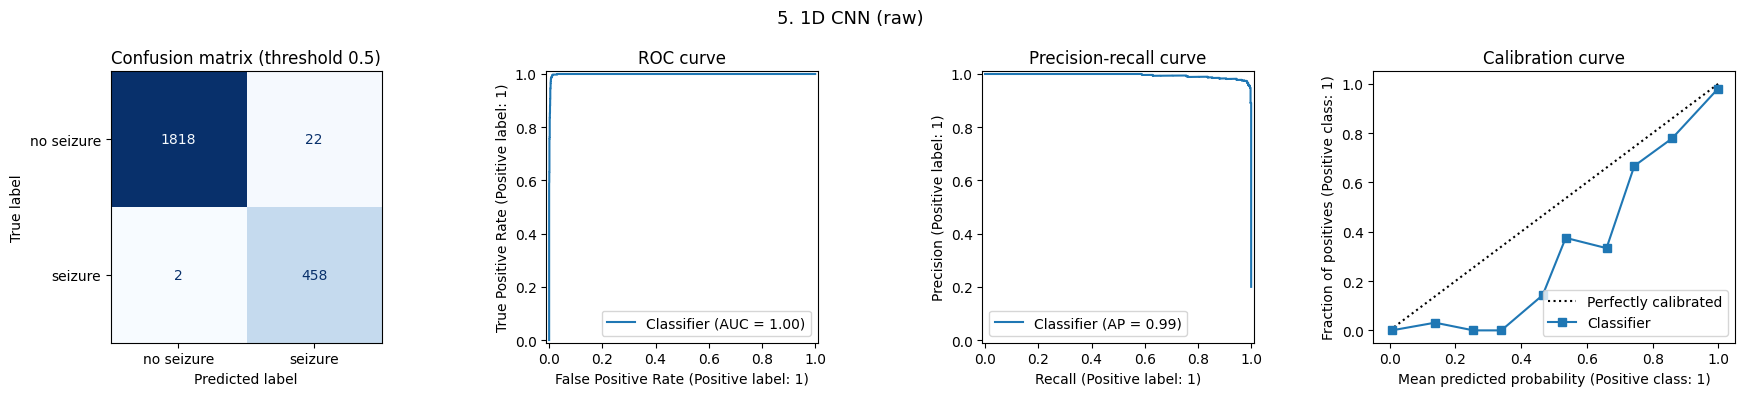

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9960,0.0095
4b. LightGBM (features),454.0,18.0,1822.0,6.0,0.9896,0.9870,0.9902,0.9619,0.9967,0.9994,0.9976,0.0081
5. 1D CNN (raw),458.0,22.0,1818.0,2.0,0.9896,0.9957,0.9880,0.9542,0.9989,0.9988,0.9948,0.0096


In [17]:
model_5 = CNN1D(epochs=20)
train_and_evaluate("5. 1D CNN (raw)", model_5, X_train, X_val)

In [18]:
val_table = pd.DataFrame(results).T.round(4)
val_table

,TP,FP,TN,FN,accuracy,sensitivity,specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
1. LogReg (raw),57.0,3.0,1837.0,403.0,0.8235,0.1239,0.9984,0.9500,0.8201,0.5245,0.4701,0.1487
2. RandomForest (raw),460.0,16.0,1824.0,0.0,0.9930,1.0000,0.9913,0.9664,1.0000,1.0000,0.9998,0.0128
3. LightGBM (raw),459.0,4.0,1836.0,1.0,0.9978,0.9978,0.9978,0.9914,0.9995,1.0000,0.9999,0.0020
4a. LogReg (features),449.0,12.0,1828.0,11.0,0.9900,0.9761,0.9935,0.9740,0.9940,0.9989,0.9960,0.0095
4b. LightGBM (features),454.0,18.0,1822.0,6.0,0.9896,0.9870,0.9902,0.9619,0.9967,0.9994,0.9976,0.0081
5. 1D CNN (raw),458.0,22.0,1818.0,2.0,0.9896,0.9957,0.9880,0.9542,0.9989,0.9988,0.9948,0.0096
